# Multimodal Movie Genre Classification — Implementation
**Jane Nguyen (a1881053), Group 18**


Multi-label genre prediction (23 genres) from **plot summaries** (DistilBERT) and **posters** (CLIP ViT-B/32) on Simplified MM-IMDb (25,959 movies).

| Section | Content |
|---|---|
| 1 | Setup & configuration |
| 2 | Data loading & quality assessment |
| 3 | Leakage-safe train/val/test split |
| 4 | Feature extraction (frozen encoders, cached) |
| 5 | Feature-variant selection |
| 6 | Models: unimodal baselines, early fusion, late fusion, GMU |
| 7 | Evaluation: metrics, thresholds, overfitting, significance |
| 8 | Analysis: per-genre, fusion behaviour, missing modality, efficiency |
| 9 | Error & bias analysis |
| 10 | Summary |

## 1. Setup & configuration

In [1]:
import os, json, time, zipfile, hashlib, random, platform, warnings
warnings.filterwarnings("ignore", message="IProgress not found")
os.environ["TRANSFORMERS_VERBOSITY"] = "error"
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import (f1_score, average_precision_score, roc_auc_score,
                             hamming_loss, precision_score, recall_score)
from scipy.stats import spearmanr

In [2]:
# Configs
CFG = {
    "data_dir": "data", "feat_dir": "features", "res_dir": "results", "fig_dir": "figures",
    "seed": 42, "seeds": [42, 7, 2026], # 3 seeds for mean ± sd
    "split": (0.60, 0.10, 0.30),
    "text_model": "distilbert/distilbert-base-uncased", "max_tokens": 256,
    "image_model": "openai/clip-vit-base-patch32",
    "hidden": 256, "dropout": 0.3, "lr": 1e-3, "weight_decay": 1e-4,
    "batch_size": 256, "max_epochs": 60, "patience": 8,
    "modality_dropout": 0.3,
    "thr_grid": np.round(np.arange(0.05, 0.96, 0.01), 2),
    "w_grid": np.round(np.arange(0.0, 1.01, 0.05), 2),
    "n_boot": 1000,
}
for d in ["feat_dir", "res_dir", "fig_dir"]:
    os.makedirs(CFG[d], exist_ok=True)

GENRES = ["Drama", "Comedy", "Romance", "Thriller", "Crime", "Action", "Adventure", "Horror",
          "Documentary", "Mystery", "Sci-Fi", "Music", "Fantasy", "Family", "Biography", "War",
          "History", "Animation", "Musical", "Western", "Sport", "Short", "Film-Noir"]

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)

set_seed(CFG["seed"])
torch.set_num_threads(os.cpu_count())
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Plot style
plt.rcParams.update({"font.family": "serif", "font.serif": ["Times New Roman", "Liberation Serif", "DejaVu Serif"],
                     "font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": "#8a8984", "axes.grid": True, "grid.color": "#e6e5e1",
                     "grid.linewidth": 0.6, "axes.axisbelow": True, "figure.dpi": 110, "savefig.dpi": 300,
                     "savefig.bbox": "tight"})
PAL = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ = "Blues"

def savefig(name):
    plt.savefig(f"{CFG['fig_dir']}/{name}.png"); plt.show()

print(f"Python {platform.python_version()} | torch {torch.__version__} | device {DEVICE} | threads {torch.get_num_threads()}")

Python 3.14.0 | torch 2.13.0 | device cpu | threads 10


## 2. Data loading & quality assessment
`images.npz` is stored uncompressed (3.2 GB), so posters are **memory-mapped** instead of loaded into RAM.

In [3]:
def memmap_npz(path, key="images.npy"):
    """Memory-map an array stored uncompressed inside an .npz archive."""
    info = zipfile.ZipFile(path).getinfo(key)
    assert info.compress_type == zipfile.ZIP_STORED, "array must be stored uncompressed"
    with open(path, "rb") as f:
        f.seek(info.header_offset)
        h = f.read(30)
        f.seek(info.header_offset + 30 + int.from_bytes(h[26:28], "little") + int.from_bytes(h[28:30], "little"))
        ver = np.lib.format.read_magic(f)
        shape, fortran, dtype = (np.lib.format.read_array_header_1_0 if ver == (1, 0)
                                 else np.lib.format.read_array_header_2_0)(f)
        offset = f.tell()
    return np.memmap(path, dtype=dtype, mode="r", shape=shape, offset=offset)

records = np.load(f"{CFG['data_dir']}/data.npy", allow_pickle=True)
images = memmap_npz(f"{CFG['data_dir']}/images.npz")
labels = np.stack([np.asarray(r, dtype=np.int64) for r in records[:, 1]])
summaries = [str(s) for s in records[:, 2]]
N, C = labels.shape
print("Records:", records.shape, "| Images:", images.shape, images.dtype, "| Labels:", labels.shape)

Records: (25959, 3) | Images: (25959, 3, 256, 160) uint8 | Labels: (25959, 23)


In [4]:
# Integrity checks
n_words = np.array([len(s.split()) for s in summaries])
quality = {
    "IDs sequential": records[:, 0].tolist() == list(range(N)),
    "Record/image counts match": len(records) == len(images),
    "Empty summaries": int(sum(not s.strip() for s in summaries)),
    "Labels binary": bool(np.isin(labels, [0, 1]).all()),
    "Movies without a genre": int((labels.sum(1) == 0).sum()),
    "Summary words (min/median/max)": f"{n_words.min()}/{int(np.median(n_words))}/{n_words.max()}",
    "Summaries < 10 words": int((n_words < 10).sum()),
    "Mean genres per movie": round(labels.sum(1).mean(), 2),
    "Multi-label share": f"{(labels.sum(1) > 1).mean():.1%}",
}
pd.Series(quality, name="value").to_frame()

,value
IDs sequential,True
Record/image counts match,True
Empty summaries,0
Labels binary,True
Movies without a genre,0
Summary words (min/median/max),1/107/1887
Summaries < 10 words,144
Mean genres per movie,2.48
Multi-label share,77.0%


In [5]:
# Duplicate detection: identical summaries and byte-identical posters
plot_groups = defaultdict(list)
for i, s in enumerate(summaries):
    plot_groups[s].append(i)
dup_plots = [g for g in plot_groups.values() if len(g) > 1]

img_groups = defaultdict(list)
for i in range(N):
    img_groups[hashlib.md5(images[i].tobytes()).digest()].append(i)
    
dup_imgs = [g for g in img_groups.values() if len(g) > 1]
dup_img_rows = np.array(sorted(i for g in dup_imgs for i in g))
conflicting = sum(len({tuple(labels[i]) for i in g}) > 1 for g in dup_imgs)
print(f"Duplicate-summary groups: {len(dup_plots)} | duplicate-poster groups: {len(dup_imgs)} ")

Duplicate-summary groups: 11 | duplicate-poster groups: 63 


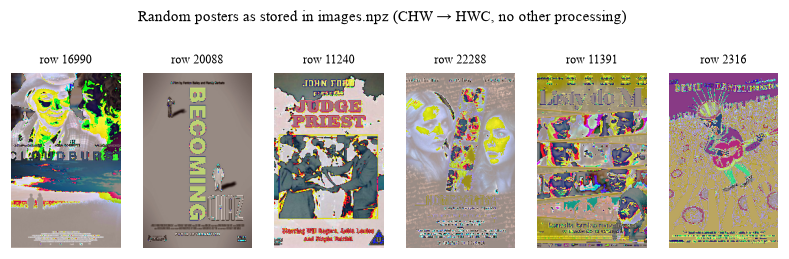

Text is pre-normalised: lower-cased, tokenised with spaces, digits replaced by 'N' -> 28.0% of summaries contain the 'N' placeholder


In [6]:
# Visual check: posters show colour wrap-around artefacts in the source arrays
rng_vis = np.random.default_rng(CFG["seed"])
fig, axes = plt.subplots(1, 6, figsize=(9, 2.6))
for ax, i in zip(axes, rng_vis.choice(N, 6, replace=False)):
    ax.imshow(np.transpose(images[i], (1, 2, 0))); ax.axis("off"); ax.set_title(f"row {i}", fontsize=8)
fig.suptitle("Random posters as stored in images.npz (CHW → HWC, no other processing)", y=1.02, fontsize=10)
savefig("figA2_poster_samples")
print("Text is pre-normalised: lower-cased, tokenised with spaces, digits replaced by 'N' ->",
      f"{np.mean([' N ' in f' {s} ' for s in summaries]):.1%} of summaries contain the 'N' placeholder")

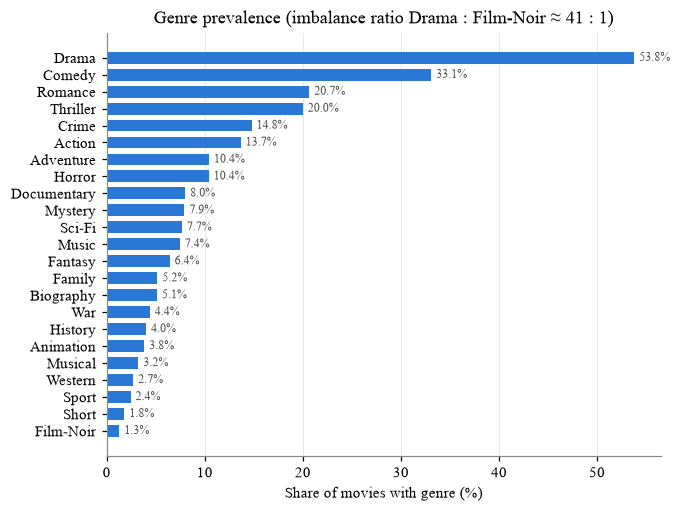

In [7]:
# Genre imbalance
prev = labels.mean(0)
order = np.argsort(prev)
fig, ax = plt.subplots(figsize=(6.5, 5))
ax.barh(np.array(GENRES)[order], prev[order] * 100, color=PAL[0], height=0.7)
for y, v in enumerate(prev[order] * 100):
    ax.text(v + 0.5, y, f"{v:.1f}%", va="center", fontsize=8, color="#52514e")
ax.set_xlabel("Share of movies with genre (%)"); ax.grid(axis="y", visible=False)
ax.set_title("Genre prevalence (imbalance ratio Drama : Film-Noir ≈ %.0f : 1)" % (prev.max() / prev.min()))
savefig("figA1_genre_prevalence")

## 3. Leakage-safe split (60/10/30)
Duplicate summaries/posters are merged into groups (union-find), and `GroupShuffleSplit` (seed 42) keeps each group in one split.

In [8]:
parent = np.arange(N)
def find(i):
    while parent[i] != i:
        parent[i] = parent[parent[i]]; i = parent[i]
    return i
for g in dup_plots + dup_imgs:
    for i in g[1:]:
        parent[find(i)] = find(g[0])
group_ids = np.array([find(i) for i in range(N)])

idx = np.arange(N)
tv_pos, te_pos = next(GroupShuffleSplit(1, test_size=0.30, random_state=CFG["seed"]).split(idx, groups=group_ids))
tv_idx, test_idx = idx[tv_pos], idx[te_pos]
tr_pos, va_pos = next(GroupShuffleSplit(1, test_size=1/7, random_state=CFG["seed"]).split(tv_idx, groups=group_ids[tv_idx]))
train_idx, val_idx = tv_idx[tr_pos], tv_idx[va_pos]

sets = [set(group_ids[s]) for s in (train_idx, val_idx, test_idx)]
assert not (sets[0] & sets[1]) and not (sets[0] & sets[2]) and not (sets[1] & sets[2])
assert len(train_idx) == 15581 and len(val_idx) == 2595 and len(test_idx) == 7783   # matches proposal
np.savez_compressed(f"{CFG['res_dir']}/split_indices.npz", train_idx=train_idx, val_idx=val_idx, test_idx=test_idx)

split_prev = pd.DataFrame({k: labels[s].mean(0) * 100 for k, s in
                           [("Train", train_idx), ("Val", val_idx), ("Test", test_idx)]}, index=GENRES)
print(f"Train {len(train_idx)} | Val {len(val_idx)} | Test {len(test_idx)} | group overlap 0 | "
      f"max prevalence deviation {(split_prev.sub(prev * 100, axis=0)).abs().values.max():.2f} pp")

Train 15581 | Val 2595 | Test 7783 | group overlap 0 | max prevalence deviation 1.38 pp


## 4. Feature extraction (frozen encoders, cached)
* **Text** — DistilBERT, 256 tokens; two poolings: `[CLS]` token and attention-masked **mean** of token states.
* **Image** — CLIP ViT-B/32 (resize 224 + centre crop + CLIP normalisation); two outputs: 768-d **pooled** vision state and 512-d **projected** (joint image–text space) embedding.

Embeddings are computed once and cached to `features/`. Set `RECOMPUTE = True` to rebuild.
For this run, the functions below were executed as a resumable background job on a 2-core CPU (timings saved in `features/extraction_timing.json`); a GPU reduces this to minutes.

In [9]:
RECOMPUTE = False
FEAT_FILES = {k: f"{CFG['feat_dir']}/{k}.npy" for k in ["text_cls", "text_mean", "img_pool", "img_proj"]}
TIMING_FILE = f"{CFG['feat_dir']}/extraction_timing.json"

@torch.inference_mode()
def extract_text(texts, batch=32):
    from transformers import AutoTokenizer, AutoModel
    tok = AutoTokenizer.from_pretrained(CFG["text_model"])
    model = AutoModel.from_pretrained(CFG["text_model"]).to(DEVICE).eval()
    order = np.argsort([len(t) for t in texts]) # length-sorted batches → less padding
    cls, mean = np.zeros((len(texts), 768), np.float32), np.zeros((len(texts), 768), np.float32)
    for b in range(0, len(texts), batch):
        ids = order[b:b + batch]
        enc = tok([texts[i] for i in ids], truncation=True, max_length=CFG["max_tokens"],
                  padding=True, return_tensors="pt").to(DEVICE)
        h = model(**enc).last_hidden_state
        m = enc["attention_mask"].unsqueeze(-1).float()
        cls[ids] = h[:, 0].cpu().numpy()
        mean[ids] = ((h * m).sum(1) / m.sum(1)).cpu().numpy()
        if b % (batch * 100) == 0:
            print(f"  text {b}/{len(texts)}", flush=True)
    return cls, mean

@torch.inference_mode()
def extract_image(imgs, batch=64):
    from transformers import CLIPImageProcessor, CLIPVisionModelWithProjection
    proc = CLIPImageProcessor.from_pretrained(CFG["image_model"])
    model = CLIPVisionModelWithProjection.from_pretrained(CFG["image_model"]).to(DEVICE).eval()
    pool, proj = np.zeros((len(imgs), 768), np.float32), np.zeros((len(imgs), 512), np.float32)
    for b in range(0, len(imgs), batch):
        x = [np.transpose(imgs[i], (1, 2, 0)) for i in range(b, min(b + batch, len(imgs)))]  # CHW → HWC
        px = proc(images=x, return_tensors="pt")["pixel_values"].to(DEVICE)
        p = model.vision_model(pixel_values=px).pooler_output
        pool[b:b + len(x)] = p.cpu().numpy()
        proj[b:b + len(x)] = model.visual_projection(p).cpu().numpy()
        if b % (batch * 50) == 0:
            print(f"  image {b}/{len(imgs)}", flush=True)
    return pool, proj

if RECOMPUTE or not all(os.path.exists(f) for f in FEAT_FILES.values()):
    timing = {"device": str(DEVICE), "threads": torch.get_num_threads()}
    t0 = time.perf_counter(); text_cls, text_mean = extract_text(summaries)
    timing["text_sec"] = time.perf_counter() - t0
    np.save(FEAT_FILES["text_cls"], text_cls); np.save(FEAT_FILES["text_mean"], text_mean)
    t0 = time.perf_counter(); img_pool, img_proj = extract_image(images)
    timing["image_sec"] = time.perf_counter() - t0
    np.save(FEAT_FILES["img_pool"], img_pool); np.save(FEAT_FILES["img_proj"], img_proj)
    json.dump(timing, open(TIMING_FILE, "w"), indent=2)

FEATS = {k: np.load(f) for k, f in FEAT_FILES.items()}
timing = json.load(open(TIMING_FILE))
print({k: v.shape for k, v in FEATS.items()})
print(f"Extraction on {timing['device']} ({timing['threads']} threads): text {timing['text_sec']/60:.1f} min "
      f"({N/timing['text_sec']:.1f} samples/s), image {timing['image_sec']/60:.1f} min ({N/timing['image_sec']:.1f} samples/s)")
assert all(np.isfinite(v).all() for v in FEATS.values())

{'text_cls': (25959, 768), 'text_mean': (25959, 768), 'img_pool': (25959, 768), 'img_proj': (25959, 512)}
Extraction on cpu (2 threads): text 22.1 min (19.5 samples/s), image 15.5 min (28.0 samples/s)


## 5. Models & training utilities
All heads share one trainer: BCE-with-logits with **√(neg/pos)** positive weights (moderate re-weighting for imbalance), AdamW, early stopping on validation Macro F1. Train/val curves are logged for the overfitting analysis.

In [10]:
class Unimodal(nn.Module):
    """LayerNorm → Linear(d,256) → ReLU → Dropout → Linear(256,23) on one modality."""
    def __init__(self, d, use="text", h=CFG["hidden"], p=CFG["dropout"]):
        super().__init__(); self.use = use
        self.net = nn.Sequential(nn.LayerNorm(d), nn.Linear(d, h), nn.ReLU(), nn.Dropout(p), nn.Linear(h, C))
    def forward(self, xt, xv):
        return self.net(xt if self.use == "text" else xv)

class EarlyFusion(nn.Module):
    """Per-modality LayerNorm → concatenate → joint MLP (proposal Appendix D)."""
    def __init__(self, dt, dv, h=CFG["hidden"], p=CFG["dropout"]):
        super().__init__()
        self.lt, self.lv = nn.LayerNorm(dt), nn.LayerNorm(dv)
        self.mlp = nn.Sequential(nn.Linear(dt + dv, h), nn.ReLU(), nn.Dropout(p), nn.Linear(h, C))
    def forward(self, xt, xv):
        return self.mlp(torch.cat([self.lt(xt), self.lv(xv)], 1))

class GMU(nn.Module):
    """Gated Multimodal Unit (Arevalo et al., 2017): z·tanh(Wt xt) + (1−z)·tanh(Wv xv), z = σ(Wz[xt;xv])."""
    def __init__(self, dt, dv, h=CFG["hidden"], p=CFG["dropout"]):
        super().__init__()
        self.lt, self.lv = nn.LayerNorm(dt), nn.LayerNorm(dv)
        self.ht, self.hv, self.z = nn.Linear(dt, h), nn.Linear(dv, h), nn.Linear(dt + dv, h)
        self.head = nn.Sequential(nn.Dropout(p), nn.Linear(h, C))
    def gate(self, xt, xv):
        xt, xv = self.lt(xt), self.lv(xv)
        return torch.sigmoid(self.z(torch.cat([xt, xv], 1))), torch.tanh(self.ht(xt)), torch.tanh(self.hv(xv))
    def forward(self, xt, xv):
        z, ht, hv = self.gate(xt, xv)
        return self.head(z * ht + (1 - z) * hv)

def n_params(m):
    return sum(p.numel() for p in m.parameters())

In [11]:
Y = {"train": labels[train_idx], "val": labels[val_idx], "test": labels[test_idx]}
SPLITS = {"train": train_idx, "val": val_idx, "test": test_idx}
pos = Y["train"].sum(0)
POS_WEIGHT = torch.tensor(np.sqrt((len(train_idx) - pos) / pos), dtype=torch.float32)

def macro_f1(y, p, thr=0.5):
    return f1_score(y, (p >= thr).astype(int), average="macro", zero_division=0)

@torch.inference_mode()
def predict(model, xt, xv, bs=4096):
    model.eval()
    out = [torch.sigmoid(model(torch.from_numpy(xt[i:i+bs]).to(DEVICE), torch.from_numpy(xv[i:i+bs]).to(DEVICE))).cpu().numpy()
           for i in range(0, len(xt), bs)]
    return np.concatenate(out)

def train_model(make, Xt, Xv, seed, mod_drop=0.0, verbose=False):
    """Train with early stopping on val Macro F1; returns best model + per-epoch history."""
    set_seed(seed)
    model = make().to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=CFG["lr"], weight_decay=CFG["weight_decay"])
    lossf = nn.BCEWithLogitsLoss(pos_weight=POS_WEIGHT.to(DEVICE))
    xt, xv = torch.from_numpy(Xt["train"]), torch.from_numpy(Xv["train"])
    yt = torch.from_numpy(Y["train"]).float()
    g = torch.Generator().manual_seed(seed)
    hist, best, best_state, wait = [], -1, None, 0
    t0 = time.perf_counter()
    for ep in range(CFG["max_epochs"]):
        model.train(); perm = torch.randperm(len(yt), generator=g); tot = 0.0
        for b in range(0, len(yt), CFG["batch_size"]):
            i = perm[b:b + CFG["batch_size"]]
            bt, bv, by = xt[i].to(DEVICE), xv[i].to(DEVICE), yt[i].to(DEVICE)
            if mod_drop > 0:                                  # zero one modality for a random subset
                r = torch.rand(len(i), generator=g)
                drop_t = (r < mod_drop / 2).float().unsqueeze(1).to(DEVICE)
                drop_v = ((r >= mod_drop / 2) & (r < mod_drop)).float().unsqueeze(1).to(DEVICE)
                bt, bv = bt * (1 - drop_t), bv * (1 - drop_v)
            loss = lossf(model(bt, bv), by)
            opt.zero_grad(); loss.backward(); opt.step(); tot += loss.item() * len(i)
        p_tr = predict(model, Xt["train"], Xv["train"]); p_va = predict(model, Xt["val"], Xv["val"])
        with torch.no_grad():
            vloss = lossf(torch.logit(torch.from_numpy(p_va).clamp(1e-6, 1 - 1e-6)), torch.from_numpy(Y["val"]).float()).item()
        h = {"epoch": ep + 1, "train_loss": tot / len(yt), "val_loss": vloss,
             "train_f1": macro_f1(Y["train"], p_tr), "val_f1": macro_f1(Y["val"], p_va)}
        hist.append(h)
        if h["val_f1"] > best:
            best, wait = h["val_f1"], 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            wait += 1
            if wait >= CFG["patience"]:
                break
    model.load_state_dict(best_state)
    return model, pd.DataFrame(hist), time.perf_counter() - t0

def view(feat):
    return {s: FEATS[feat][ix] for s, ix in SPLITS.items()}

### 5.1 Feature-variant selection (validation set only)
Each text and image variant is scored with the unimodal head (3 seeds). Selection uses **validation mAP** (threshold-free), so the test set stays untouched.

In [12]:
variant_rows = []
dummy = {s: np.zeros((len(ix), 1), np.float32) for s, ix in SPLITS.items()}
for feat in FEATS:
    use = "text" if feat.startswith("text") else "image"
    X = view(feat); d = X["train"].shape[1]
    for seed in CFG["seeds"]:
        Xt, Xv = (X, dummy) if use == "text" else (dummy, X)
        m, hist, _ = train_model(lambda: Unimodal(d, use), Xt, Xv, seed)
        p = predict(m, Xt["val"], Xv["val"])
        variant_rows.append({"modality": use, "feature": feat, "dim": d, "seed": seed,
                             "val_mAP": average_precision_score(Y["val"], p, average="macro"),
                             "val_macroF1@0.5": macro_f1(Y["val"], p)})
variants = pd.DataFrame(variant_rows).groupby(["modality", "feature", "dim"])[["val_mAP", "val_macroF1@0.5"]].agg(["mean", "std"]).round(4)
variants.to_csv(f"{CFG['res_dir']}/feature_variants.csv")
TEXT_FEAT = variants.loc["text"]["val_mAP"]["mean"].idxmax()[0]
IMG_FEAT = variants.loc["image"]["val_mAP"]["mean"].idxmax()[0]
print("Selected →", TEXT_FEAT, "|", IMG_FEAT)
variants

Selected → text_mean | img_pool


val_mAP         val_macroF1@0.5        
                          mean     std            mean     std
modality feature   dim                                        
image    img_pool  768  0.2856  0.0007          0.2925  0.0058
         img_proj  512  0.2821  0.0012          0.2903  0.0039
text     text_cls  768  0.6202  0.0014          0.5919  0.0023
         text_mean 768  0.6303  0.0028          0.6005  0.0034

## 6. Train all approaches (3 seeds each)
| ID | Approach | Fusion level |
|---|---|---|
| T | Text-only MLP | — |
| I | Image-only MLP | — |
| EF | Early fusion (concat + joint MLP) | feature |
| EF-MD | Early fusion + modality dropout (p = 0.3) | feature |
| GMU | Gated Multimodal Unit | intermediate (learned gate) |
| LF-avg | Late fusion, equal-weight average of T and I | decision |
| LF-w | Late fusion, per-genre weights tuned on validation | decision |

In [13]:
XT, XV = view(TEXT_FEAT), view(IMG_FEAT)
dt, dv = XT["train"].shape[1], XV["train"].shape[1]
MAKERS = {
    "T":     (lambda: Unimodal(dt, "text"), 0.0),
    "I":     (lambda: Unimodal(dv, "image"), 0.0),
    "EF":    (lambda: EarlyFusion(dt, dv), 0.0),
    "EF-MD": (lambda: EarlyFusion(dt, dv), CFG["modality_dropout"]),
    "GMU":   (lambda: GMU(dt, dv), 0.0),
}
RUNS = {}          # RUNS[(name, seed)] = dict(model, hist, train_sec, probs)
for name, (make, md) in MAKERS.items():
    for seed in CFG["seeds"]:
        m, hist, sec = train_model(make, XT, XV, seed, mod_drop=md)
        RUNS[(name, seed)] = {"model": m, "hist": hist, "train_sec": sec,
                              "probs": {s: predict(m, XT[s], XV[s]) for s in SPLITS}}
    print(f"{name:6s} params={n_params(m):,}  epochs={[len(RUNS[(name, s)]['hist']) for s in CFG['seeds']]}  "
          f"train time ≈ {np.mean([RUNS[(name, s)]['train_sec'] for s in CFG['seeds']]):.1f}s")

T      params=204,311  epochs=[32, 32, 36]  train time ≈ 3.2s
I      params=204,311  epochs=[20, 16, 19]  train time ≈ 1.7s
EF     params=402,455  epochs=[20, 19, 16]  train time ≈ 2.6s
EF-MD  params=402,455  epochs=[24, 31, 26]  train time ≈ 3.9s
GMU    params=796,183  epochs=[15, 19, 18]  train time ≈ 4.4s


In [14]:
def f1_grid(y, p, thrs):
    """Vectorised binary F1 for one genre across a grid of thresholds."""
    pred = p[:, None] >= thrs[None, :]
    tp = (pred & (y[:, None] == 1)).sum(0); fp = pred.sum(0) - tp; fn = y.sum() - tp
    return np.divide(2 * tp, 2 * tp + fp + fn, out=np.zeros(len(thrs)), where=(2 * tp + fp + fn) > 0)

def tune_thresholds(y, p):
    """Per-genre threshold maximising validation F1."""
    return np.array([CFG["thr_grid"][np.argmax(f1_grid(y[:, j], p[:, j], CFG["thr_grid"]))] for j in range(C)])

def late_fusion_weights(y, pt, pv):
    """Per-genre text weight w and threshold jointly maximising validation F1 for w·pT + (1−w)·pI."""
    W, T = np.zeros(C), np.zeros(C)
    for j in range(C):
        best = (-1, 0, 0.5)
        for w in CFG["w_grid"]:
            f = f1_grid(y[:, j], w * pt[:, j] + (1 - w) * pv[:, j], CFG["thr_grid"])
            k = int(np.argmax(f))
            if f[k] > best[0] + 1e-12:
                best = (f[k], w, CFG["thr_grid"][k])
        W[j], T[j] = best[1], best[2]
    return W, T

for seed in CFG["seeds"]:
    pT, pI = RUNS[("T", seed)]["probs"], RUNS[("I", seed)]["probs"]
    RUNS[("LF-avg", seed)] = {"probs": {s: 0.5 * pT[s] + 0.5 * pI[s] for s in SPLITS},
                              "train_sec": RUNS[("T", seed)]["train_sec"] + RUNS[("I", seed)]["train_sec"]}
    t0 = time.perf_counter()
    W, T = late_fusion_weights(Y["val"], pT["val"], pI["val"])
    RUNS[("LF-w", seed)] = {"probs": {s: W * pT[s] + (1 - W) * pI[s] for s in SPLITS}, "W": W, "thr": T,
                            "train_sec": RUNS[("LF-avg", seed)]["train_sec"] + time.perf_counter() - t0}

MODELS = ["T", "I", "EF", "EF-MD", "GMU", "LF-avg", "LF-w"]
for name in MODELS:
    for seed in CFG["seeds"]:
        r = RUNS[(name, seed)]
        if "thr" not in r:
            r["thr"] = tune_thresholds(Y["val"], r["probs"]["val"])
print("Thresholds tuned on validation for all models.")

Thresholds tuned on validation for all models.


## 7. Evaluation
### 7.1 Test-set metrics (mean ± sd over 3 seeds, per-genre thresholds tuned on validation)

In [15]:
def all_metrics(y, p, thr):
    yh = (p >= thr).astype(int)
    return {"Macro F1": f1_score(y, yh, average="macro", zero_division=0),
            "Micro F1": f1_score(y, yh, average="micro", zero_division=0),
            "Weighted F1": f1_score(y, yh, average="weighted", zero_division=0),
            "Samples F1": f1_score(y, yh, average="samples", zero_division=0),
            "Macro P": precision_score(y, yh, average="macro", zero_division=0),
            "Macro R": recall_score(y, yh, average="macro", zero_division=0),
            "mAP": average_precision_score(y, p, average="macro"),
            "ROC-AUC": roc_auc_score(y, p, average="macro"),
            "Hamming loss": hamming_loss(y, yh)}

rows = []
for name in MODELS:
    for seed in CFG["seeds"]:
        r = RUNS[(name, seed)]
        rows.append({"model": name, "seed": seed, "thr": "tuned", **all_metrics(Y["test"], r["probs"]["test"], r["thr"])})
        rows.append({"model": name, "seed": seed, "thr": "0.5", **all_metrics(Y["test"], r["probs"]["test"], 0.5)})
metrics_long = pd.DataFrame(rows)
metrics_long.to_csv(f"{CFG['res_dir']}/test_metrics_all_seeds.csv", index=False)

agg = metrics_long[metrics_long.thr == "tuned"].drop(columns=["seed", "thr"]).groupby("model").agg(["mean", "std"]).reindex(MODELS)
fmt = pd.DataFrame({c: [f"{agg.loc[m, (c, 'mean')]:.4f} ± {agg.loc[m, (c, 'std')]:.4f}" for m in MODELS]
                    for c in agg.columns.get_level_values(0).unique()}, index=MODELS)
fmt.to_csv(f"{CFG['res_dir']}/test_metrics_summary.csv")
fmt

,Macro F1,Micro F1,Weighted F1,Samples F1,Macro P,Macro R,mAP,ROC-AUC,Hamming loss
T,0.5817 ± 0.0008,0.6462 ± 0.0025,0.6457 ± 0.0013,0.6426 ± 0.0037,0.5709 ± 0.0111,0.6048 ± 0.0153,0.6049 ± 0.0009,0.9139 ± 0.0007,0.0823 ± 0.0026
I,0.3163 ± 0.0010,0.4298 ± 0.0106,0.4530 ± 0.0009,0.4254 ± 0.0110,0.2822 ± 0.0033,0.4090 ± 0.0088,0.2811 ± 0.0028,0.7443 ± 0.0016,0.1637 ± 0.0071
EF,0.5841 ± 0.0004,0.6479 ± 0.0032,0.6476 ± 0.0023,0.6435 ± 0.0039,0.5589 ± 0.0021,0.6246 ± 0.0031,0.6124 ± 0.0020,0.9169 ± 0.0003,0.0833 ± 0.0006
EF-MD,0.5878 ± 0.0036,0.6499 ± 0.0017,0.6516 ± 0.0006,0.6468 ± 0.0033,0.5691 ± 0.0061,0.6246 ± 0.0089,0.6138 ± 0.0010,0.9170 ± 0.0011,0.0829 ± 0.0009
GMU,0.5909 ± 0.0026,0.6492 ± 0.0022,0.6513 ± 0.0013,0.6455 ± 0.0042,0.5677 ± 0.0054,0.6278 ± 0.0071,0.6190 ± 0.0009,0.9191 ± 0.0005,0.0817 ± 0.0014
LF-avg,0.5919 ± 0.0033,0.6517 ± 0.0028,0.6544 ± 0.0008,0.6461 ± 0.0029,0.5719 ± 0.0145,0.6248 ± 0.0142,0.5956 ± 0.0037,0.9104 ± 0.0012,0.0808 ± 0.0020
LF-w,0.5950 ± 0.0051,0.6570 ± 0.0013,0.6576 ± 0.0021,0.6525 ± 0.0016,0.5836 ± 0.0061,0.6193 ± 0.0086,0.6147 ± 0.0029,0.9170 ± 0.0010,0.0795 ± 0.0008


In [16]:
# Effect of threshold tuning on Macro F1
thr_eff = metrics_long.groupby(["model", "thr"])["Macro F1"].mean().unstack().reindex(MODELS)[["0.5", "tuned"]]
thr_eff["gain"] = thr_eff["tuned"] - thr_eff["0.5"]
thr_eff.round(4)

thr,0.5,tuned,gain
model,,,
T,0.5788,0.5817,0.0030
I,0.2888,0.3163,0.0274
EF,0.5833,0.5841,0.0008
EF-MD,0.5883,0.5878,-0.0005
GMU,0.5893,0.5909,0.0016
LF-avg,0.5527,0.5919,0.0393
LF-w,0.5807,0.5950,0.0143


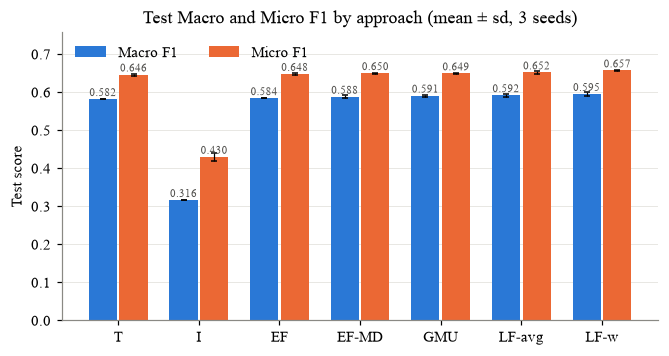

In [17]:
# Figure: model comparison
fig, ax = plt.subplots(figsize=(7, 3.4))
x = np.arange(len(MODELS)); w = 0.38
for k, (met, col) in enumerate([("Macro F1", PAL[0]), ("Micro F1", PAL[1])]):
    mu, sd = agg[(met, "mean")].values, agg[(met, "std")].values
    ax.bar(x + (k - 0.5) * w, mu, w * 0.92, yerr=sd, capsize=2, color=col, label=met, error_kw={"lw": 0.8})
    for xi, v in zip(x + (k - 0.5) * w, mu):
        ax.text(xi, v + 0.008, f"{v:.3f}", ha="center", fontsize=7, color="#52514e")
ax.set_xticks(x, MODELS); ax.set_ylabel("Test score"); ax.set_ylim(0, max(agg[("Micro F1", "mean")]) + 0.1)
ax.legend(frameon=False, ncol=2, loc="upper left"); ax.grid(axis="x", visible=False)
ax.set_title("Test Macro and Micro F1 by approach (mean ± sd, 3 seeds)")
savefig("fig2_model_comparison")

### 7.2 Overfitting assessment
Generalisation gap = train Macro F1 − validation Macro F1 at the selected epoch (threshold 0.5, seed 42 curves shown).

In [18]:
gap_rows = []
for name in ["T", "I", "EF", "EF-MD", "GMU"]:
    for seed in CFG["seeds"]:
        h = RUNS[(name, seed)]["hist"]; b = h["val_f1"].idxmax()
        gap_rows.append({"model": name, "best_epoch": h.loc[b, "epoch"], "train_F1": h.loc[b, "train_f1"],
                         "val_F1": h.loc[b, "val_f1"], "gap": h.loc[b, "train_f1"] - h.loc[b, "val_f1"],
                         "final_gap": h["train_f1"].iloc[-1] - h["val_f1"].iloc[-1]})
for name in ["LF-avg", "LF-w"]:
    for seed in CFG["seeds"]:
        r = RUNS[(name, seed)]
        tr, va = macro_f1(Y["train"], r["probs"]["train"]), macro_f1(Y["val"], r["probs"]["val"])
        gap_rows.append({"model": name, "best_epoch": np.nan, "train_F1": tr, "val_F1": va, "gap": tr - va, "final_gap": np.nan})
gaps = pd.DataFrame(gap_rows).groupby("model").mean().reindex(MODELS).round(4)
gaps.to_csv(f"{CFG['res_dir']}/overfitting_gaps.csv")
gaps

,best_epoch,train_F1,val_F1,gap,final_gap
model,,,,,
T,25.3333,0.6601,0.6005,0.0596,0.0885
I,10.3333,0.4308,0.2925,0.1383,0.2836
EF,10.3333,0.6923,0.6056,0.0868,0.1635
EF-MD,19.0000,0.7321,0.6043,0.1277,0.1846
GMU,9.3333,0.7028,0.6100,0.0929,0.2027
LF-avg,NaN,0.7002,0.5797,0.1205,NaN
LF-w,NaN,0.6992,0.6090,0.0902,NaN


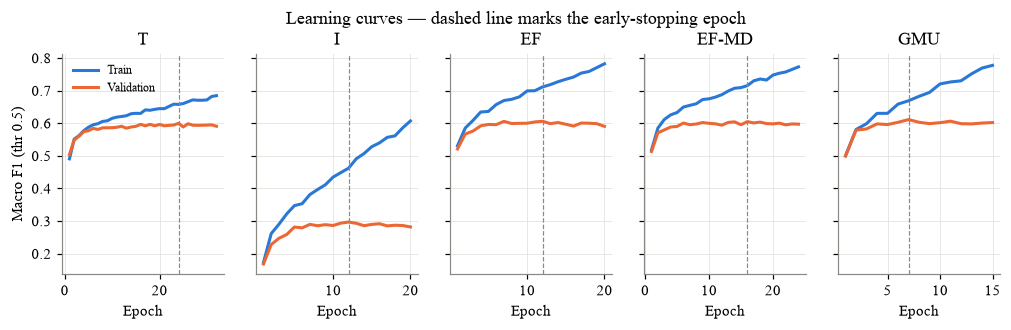

In [19]:
fig, axes = plt.subplots(1, 5, figsize=(11, 2.6), sharey=True)
for ax, name in zip(axes, ["T", "I", "EF", "EF-MD", "GMU"]):
    h = RUNS[(name, CFG["seed"])]["hist"]
    ax.plot(h.epoch, h.train_f1, color=PAL[0], lw=2, label="Train")
    ax.plot(h.epoch, h.val_f1, color=PAL[1], lw=2, label="Validation")
    ax.axvline(h.loc[h.val_f1.idxmax(), "epoch"], color="#8a8984", ls="--", lw=0.8)
    ax.set_title(name); ax.set_xlabel("Epoch")
axes[0].set_ylabel("Macro F1 (thr 0.5)"); axes[0].legend(frameon=False, fontsize=8)
fig.suptitle("Learning curves — dashed line marks the early-stopping epoch", y=1.03)
savefig("fig3_learning_curves")

### 7.3 Statistical significance (paired bootstrap on the test set, seed 42)

In [20]:
def boot_diff(a, b, n=CFG["n_boot"], seed=0):
    """Paired bootstrap of Macro F1(a) − Macro F1(b); returns mean diff, 95% CI, P(diff ≤ 0)."""
    rng = np.random.default_rng(seed); y = Y["test"]
    ya = (RUNS[(a, CFG["seed"])]["probs"]["test"] >= RUNS[(a, CFG["seed"])]["thr"]).astype(int)
    yb = (RUNS[(b, CFG["seed"])]["probs"]["test"] >= RUNS[(b, CFG["seed"])]["thr"]).astype(int)
    d = []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y))
        d.append(f1_score(y[i], ya[i], average="macro", zero_division=0) - f1_score(y[i], yb[i], average="macro", zero_division=0))
    d = np.array(d)
    return {"comparison": f"{a} − {b}", "ΔMacro F1": d.mean(), "CI low": np.percentile(d, 2.5),
            "CI high": np.percentile(d, 97.5), "p (Δ≤0)": (d <= 0).mean()}

BEST = agg[("Macro F1", "mean")].idxmax()
pairs = [(BEST, "T"), (BEST, "I")] + [(m, "T") for m in ["EF", "EF-MD", "GMU", "LF-avg", "LF-w"] if m != BEST] + [("EF", "LF-w")]
boot = pd.DataFrame([boot_diff(a, b) for a, b in pairs]).round(4)
boot.to_csv(f"{CFG['res_dir']}/bootstrap.csv", index=False)
print("Best model by mean test Macro F1:", BEST)
boot

Best model by mean test Macro F1: LF-w


,comparison,ΔMacro F1,CI low,CI high,p (Δ≤0)
0,LF-w − T,0.0198,0.0141,0.0256,0.000
1,LF-w − I,0.2844,0.2746,0.2949,0.000
2,EF − T,0.0026,-0.0047,0.0101,0.255
3,EF-MD − T,0.0063,-0.0013,0.0132,0.046
4,GMU − T,0.0105,0.0033,0.0173,0.002
5,LF-avg − T,0.0117,0.0047,0.0187,0.000
6,EF − LF-w,-0.0172,-0.0237,-0.0107,1.000


## 8. Analysis
### 8.1 Per-genre F1

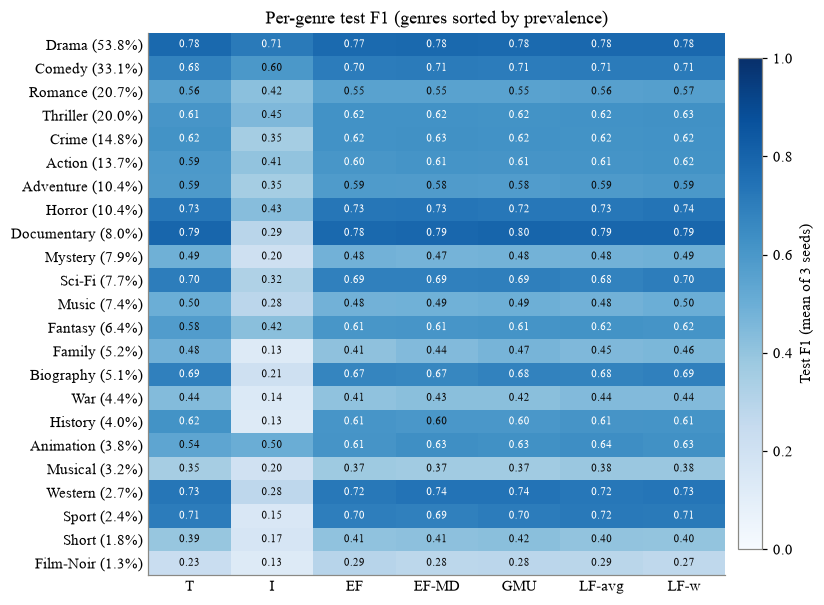

In [21]:
def per_genre_f1(name, seed=None):
    seeds = CFG["seeds"] if seed is None else [seed]
    return np.mean([f1_score(Y["test"], (RUNS[(name, s)]["probs"]["test"] >= RUNS[(name, s)]["thr"]).astype(int),
                             average=None, zero_division=0) for s in seeds], axis=0)

pg = pd.DataFrame({m: per_genre_f1(m) for m in MODELS}, index=GENRES)
pg.insert(0, "prevalence %", prev * 100)
pg = pg.sort_values("prevalence %", ascending=False)
pg.round(3).to_csv(f"{CFG['res_dir']}/per_genre_f1.csv")

fig, ax = plt.subplots(figsize=(7.2, 6.4))
M = pg[MODELS].values
im = ax.imshow(M, cmap=SEQ, vmin=0, vmax=1, aspect="auto")
for i in range(M.shape[0]):
    for j in range(M.shape[1]):
        ax.text(j, i, f"{M[i, j]:.2f}", ha="center", va="center", fontsize=7, color="white" if M[i, j] > 0.6 else "#0b0b0b")
ax.set_xticks(range(len(MODELS)), MODELS); ax.set_yticks(range(len(pg)), [f"{g} ({p:.1f}%)" for g, p in zip(pg.index, pg["prevalence %"])])
ax.grid(False); ax.tick_params(length=0)
cb = fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02); cb.set_label("Test F1 (mean of 3 seeds)")
ax.set_title("Per-genre test F1 (genres sorted by prevalence)")
savefig("fig4_per_genre_heatmap")

In [22]:
rho, pval = spearmanr(pg["prevalence %"], pg[BEST])
gain_vs_text = (pg[BEST] - pg["T"]).sort_values()
print(f"Spearman ρ(prevalence, {BEST} F1) = {rho:.2f} (p = {pval:.3g})")
print(f"Largest fusion gains over text ({BEST} − T):\n{gain_vs_text.tail(5).round(3).to_string()}")
print(f"Smallest/negative:\n{gain_vs_text.head(3).round(3).to_string()}")

Spearman ρ(prevalence, LF-w F1) = 0.38 (p = 0.0733)
Largest fusion gains over text (LF-w − T):
Action       0.027
Musical      0.034
Film-Noir    0.038
Fantasy      0.039
Animation    0.090
Smallest/negative:
Family    -0.024
History   -0.004
Mystery    0.000


### 8.2 How the fusion models use each modality
Late-fusion text weight *w* per genre and the mean GMU gate *z* (share routed through the text branch) on the test set.

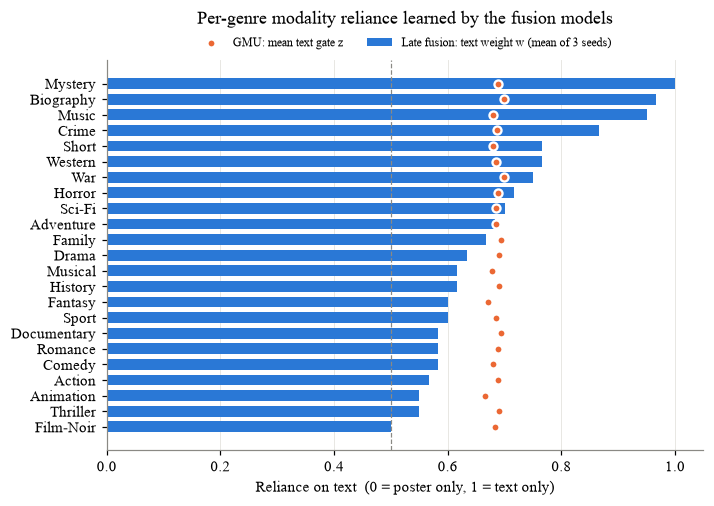

Spearman ρ(LF-w weight, GMU gate) = 0.16


In [23]:
W_mean = np.mean([RUNS[("LF-w", s)]["W"] for s in CFG["seeds"]], axis=0)
gm = RUNS[("GMU", CFG["seed"])]["model"].eval()
with torch.inference_mode():
    z, _, _ = gm.gate(torch.from_numpy(XT["test"]).to(DEVICE), torch.from_numpy(XV["test"]).to(DEVICE))
z = z.mean(1).cpu().numpy()                                      # per-sample mean gate
z_genre = np.array([z[Y["test"][:, j] == 1].mean() for j in range(C)])
mod_use = pd.DataFrame({"LF-w text weight": W_mean, "GMU mean gate (text)": z_genre,
                        "I − T F1": pg.reindex(GENRES)["I"].values - pg.reindex(GENRES)["T"].values}, index=GENRES).sort_values("LF-w text weight")
mod_use.round(3).to_csv(f"{CFG['res_dir']}/modality_use.csv")

fig, ax = plt.subplots(figsize=(7, 4.6))
yy = np.arange(C)
ax.barh(yy, mod_use["LF-w text weight"], height=0.7, color=PAL[0], label="Late fusion: text weight w (mean of 3 seeds)")
ax.scatter(mod_use["GMU mean gate (text)"], yy, color=PAL[1], s=28, zorder=3, edgecolor="white", linewidth=1.5, label="GMU: mean text gate z")
ax.axvline(0.5, color="#8a8984", ls="--", lw=0.8)
ax.set_yticks(yy, mod_use.index); ax.set_xlim(0, 1.05); ax.set_xlabel("Reliance on text  (0 = poster only, 1 = text only)")
ax.grid(axis="y", visible=False)
ax.legend(frameon=False, fontsize=8, loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2)
ax.set_title("Per-genre modality reliance learned by the fusion models", pad=24)
savefig("fig5_modality_reliance")
print(f"Spearman ρ(LF-w weight, GMU gate) = {spearmanr(mod_use.iloc[:, 0], mod_use.iloc[:, 1])[0]:.2f}")

### 8.3 Robustness to a missing modality (seed 42, test set)
The text or poster input is zeroed at test time. Late fusion falls back to the available unimodal classifier.

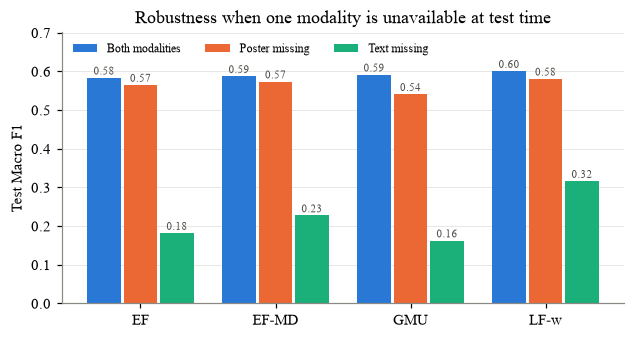

,Both modalities,Poster missing,Text missing
EF,0.5837,0.5650,0.1820
EF-MD,0.5874,0.5737,0.2275
GMU,0.5916,0.5412,0.1626
LF-w,0.6009,0.5810,0.3165


In [24]:
def missing_eval(name, drop):
    s = CFG["seed"]; zt, zv = np.zeros_like(XT["test"]), np.zeros_like(XV["test"])
    if name.startswith("LF"):
        r = RUNS[(name, s)]; pT, pI = RUNS[("T", s)]["probs"]["test"], RUNS[("I", s)]["probs"]["test"]
        if drop == "none":
            p, thr = r["probs"]["test"], r["thr"]
        else:   # fallback to the surviving unimodal model and its own thresholds
            keep = "I" if drop == "text" else "T"
            p, thr = (pI if keep == "I" else pT), RUNS[(keep, s)]["thr"]
    else:
        m = RUNS[(name, s)]["model"]; r = RUNS[(name, s)]
        xt = zt if drop == "text" else XT["test"]; xv = zv if drop == "image" else XV["test"]
        p, thr = predict(m, xt, xv), r["thr"]
    return f1_score(Y["test"], (p >= thr).astype(int), average="macro", zero_division=0)

robust = pd.DataFrame({d: {m: missing_eval(m, d) for m in ["EF", "EF-MD", "GMU", "LF-w"]}
                       for d in ["none", "image", "text"]})
robust.columns = ["Both modalities", "Poster missing", "Text missing"]
robust.round(4).to_csv(f"{CFG['res_dir']}/missing_modality.csv")

fig, ax = plt.subplots(figsize=(6.6, 3.2))
x = np.arange(len(robust)); w = 0.27
for k, c in enumerate(robust.columns):
    ax.bar(x + (k - 1) * w, robust[c], w * 0.92, color=PAL[k], label=c)
    for xi, v in zip(x + (k - 1) * w, robust[c]):
        ax.text(xi, v + 0.008, f"{v:.2f}", ha="center", fontsize=7, color="#52514e")
ax.set_xticks(x, robust.index); ax.set_ylabel("Test Macro F1"); ax.set_ylim(0, robust.values.max() + 0.1)
ax.legend(frameon=False, ncol=3, fontsize=8, loc="upper left"); ax.grid(axis="x", visible=False)
ax.set_title("Robustness when one modality is unavailable at test time")
savefig("fig6_missing_modality")
robust.round(4)

### 8.4 Efficiency

In [25]:
@torch.inference_mode()
def time_inference(name, reps=5):
    s = CFG["seed"]
    if name.startswith("LF"):
        return time_inference("T", reps) + time_inference("I", reps)
    m = RUNS[(name, s)]["model"]; ts = []
    for _ in range(reps):
        t0 = time.perf_counter(); predict(m, XT["test"], XV["test"]); ts.append(time.perf_counter() - t0)
    return np.median(ts) / len(test_idx) * 1000 * 1000  # ms per 1,000 movies

eff = pd.DataFrame({
    "Trainable params": [n_params(RUNS[(m if not m.startswith("LF") else "T", CFG["seed"])]["model"]) +
                         (n_params(RUNS[("I", CFG["seed"])]["model"]) if m.startswith("LF") else 0) + (C if m == "LF-w" else 0)
                         for m in MODELS],
    "Train time (s)": [np.mean([RUNS[(m, s)]["train_sec"] for s in CFG["seeds"]]) for m in MODELS],
    "Head inference (ms / 1k movies)": [time_inference(m) for m in MODELS],
    "Test Macro F1": agg[("Macro F1", "mean")].values,
}, index=MODELS)
eff.round(3).to_csv(f"{CFG['res_dir']}/efficiency.csv")
print(f"Frozen-encoder cost (one-off, {timing['device']}): DistilBERT {N/timing['text_sec']:.1f} movies/s, "
      f"CLIP {N/timing['image_sec']:.1f} movies/s → encoders dominate end-to-end cost.")
eff.round(3)

Frozen-encoder cost (one-off, cpu): DistilBERT 19.5 movies/s, CLIP 28.0 movies/s → encoders dominate end-to-end cost.


,Trainable params,Train time (s),Head inference (ms / 1k movies),Test Macro F1
T,204311,3.185,0.400,0.582
I,204311,1.747,0.380,0.316
EF,402455,2.560,0.898,0.584
EF-MD,402455,3.905,0.905,0.588
GMU,796183,4.410,1.748,0.591
LF-avg,408622,4.932,0.735,0.592
LF-w,408645,5.081,0.751,0.595


## 9. Error & bias analysis (best model, seed 42)

In [26]:
rb = RUNS[(BEST, CFG["seed"])]
P_best = rb["probs"]["test"]; Yh = (P_best >= rb["thr"]).astype(int); Yt = Y["test"]
samp_f1 = np.array([f1_score(Yt[i], Yh[i], zero_division=0) for i in range(len(Yt))])
card = Yt.sum(1)
words_te = n_words[test_idx]
tok_trunc = None
try:
    from transformers import AutoTokenizer
    _tok = AutoTokenizer.from_pretrained(CFG["text_model"])
    tok_len = np.array([len(x) for x in _tok([summaries[i] for i in test_idx], truncation=False)["input_ids"]])
    tok_trunc = tok_len > CFG["max_tokens"]
except Exception as e:
    print("Tokenizer unavailable:", e)

def grp(mask_dict):
    return pd.DataFrame({k: {"n": int(v.sum()), "Samples F1": samp_f1[v].mean(),
                             "Macro F1": f1_score(Yt[v], Yh[v], average="macro", zero_division=0)} for k, v in mask_dict.items()}).T

q = np.quantile(words_te, [0.25, 0.5, 0.75])
subgroups = pd.concat({
    "Label cardinality": grp({"1 genre": card == 1, "2 genres": card == 2, "3 genres": card == 3, "4+ genres": card >= 4}),
    "Summary length": grp({f"Q1 (≤{int(q[0])} words)": words_te <= q[0], "Q2": (words_te > q[0]) & (words_te <= q[1]),
                           "Q3": (words_te > q[1]) & (words_te <= q[2]), f"Q4 (>{int(q[2])} words)": words_te > q[2]}),
    "Poster": grp({"unique poster": ~np.isin(test_idx, dup_img_rows), "duplicate/placeholder poster": np.isin(test_idx, dup_img_rows)}),
    **({"Truncation": grp({"≤256 tokens": ~tok_trunc, ">256 tokens (truncated)": tok_trunc})} if tok_trunc is not None else {}),
})
subgroups["Samples F1"] = subgroups["Samples F1"].astype(float).round(3); subgroups["Macro F1"] = subgroups["Macro F1"].astype(float).round(3)
subgroups.to_csv(f"{CFG['res_dir']}/subgroup_errors.csv")
subgroups

n  Samples F1  Macro F1
Label cardinality 1 genre                       1751.0       0.610     0.260
                  2 genres                      2512.0       0.664     0.555
                  3 genres                      2062.0       0.671     0.621
                  4+ genres                     1458.0       0.668     0.636
Summary length    Q1 (≤59 words)                1949.0       0.625     0.560
                  Q2                            1957.0       0.647     0.587
                  Q3                            1939.0       0.672     0.628
                  Q4 (>157 words)               1938.0       0.674     0.602
Poster            unique poster                 7743.0       0.655     0.602
                  duplicate/placeholder poster    40.0       0.499     0.354
Truncation        ≤256 tokens                   6990.0       0.652     0.599
                  >256 tokens (truncated)        793.0       0.673     0.585

In [27]:
# Predicted vs true label count (over/under-prediction) and most frequent false positives/negatives
fp = ((Yh == 1) & (Yt == 0)).sum(0); fn = ((Yh == 0) & (Yt == 1)).sum(0)
err = pd.DataFrame({"support": Yt.sum(0), "predicted": Yh.sum(0), "FP": fp, "FN": fn,
                    "precision": precision_score(Yt, Yh, average=None, zero_division=0),
                    "recall": recall_score(Yt, Yh, average=None, zero_division=0)}, index=GENRES).sort_values("support", ascending=False)
err.round(3).to_csv(f"{CFG['res_dir']}/error_breakdown.csv")
print(f"Mean true labels/movie {card.mean():.2f} vs predicted {Yh.sum(1).mean():.2f}; "
      f"movies with zero predicted genres: {(Yh.sum(1) == 0).sum()}")

# Genre confusions: for FN of genre a, which wrong genre b was predicted most often
conf = np.zeros((C, C), int)
for a in range(C):
    miss = (Yt[:, a] == 1) & (Yh[:, a] == 0)
    conf[a] = ((Yh[miss] == 1) & (Yt[miss] == 0)).sum(0)
top_conf = sorted([(conf[a, b], GENRES[a], GENRES[b]) for a in range(C) for b in range(C) if a != b], reverse=True)[:8]
print("Top substitution errors (missed → predicted instead):", [(f"{a}→{b}", n) for n, a, b in top_conf])
err.round(3)

Mean true labels/movie 2.48 vs predicted 2.81; movies with zero predicted genres: 24
Top substitution errors (missed → predicted instead): [('Comedy→Drama', np.int64(203)), ('Comedy→Thriller', np.int64(167)), ('Comedy→Crime', np.int64(97)), ('Action→Drama', np.int64(92)), ('Drama→Comedy', np.int64(87)), ('Comedy→Romance', np.int64(85)), ('Romance→Drama', np.int64(83)), ('Romance→Crime', np.int64(81))]


,support,predicted,FP,FN,precision,recall
Drama,4157,4932,1364,589,0.723,0.858
Comedy,2558,2432,665,791,0.727,0.691
Romance,1570,1903,925,592,0.514,0.623
Thriller,1539,2026,907,420,0.552,0.727
Crime,1194,1734,824,284,0.525,0.762
Action,1038,1135,460,363,0.595,0.650
Horror,872,914,255,213,0.721,0.756
Adventure,802,833,350,319,0.580,0.602
Mystery,641,811,455,285,0.439,0.555
Documentary,617,598,112,131,0.813,0.788


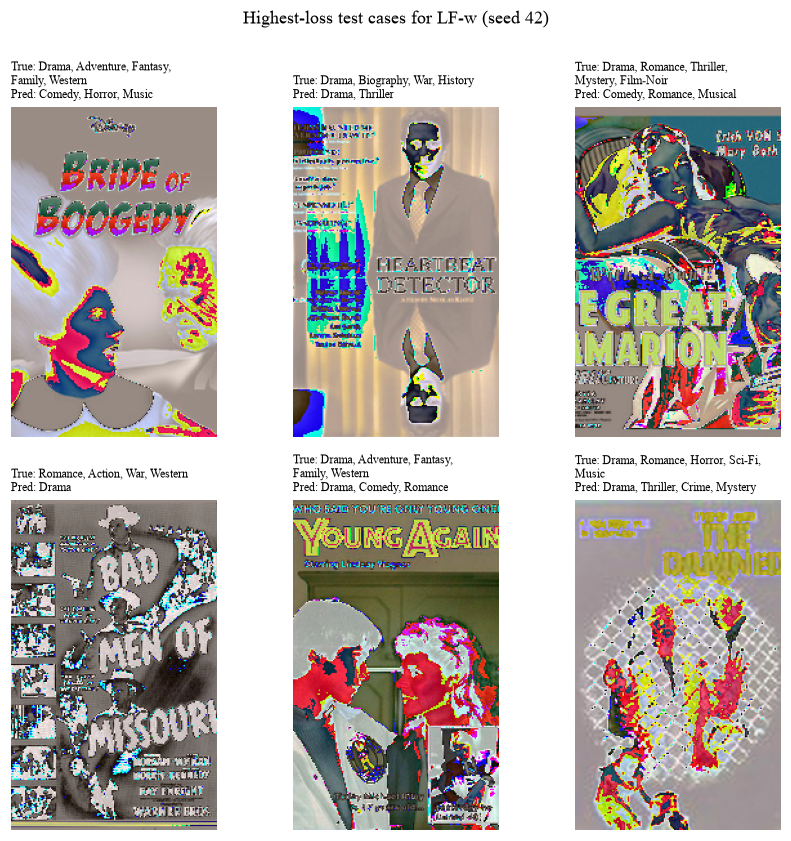

[1145] one year after the davis family defeated the hideous ghost of mr . boogedy , the evil spirit returns once again from beyond the grave by haunting the dreams of ...
[19433] paris today . simon works as psychologist in human resources department of petrochemical corporation . when management gets him to investigate one of the factor...
[18165] flamarion , expert marksman , is entertaining people in a show which features connie , beautiful woman and her husband al . flamarion and connie fall in love an...
[15727] the younger brothers , cole (...
[18749] michael riley whishes to be N again and which comes true . he goes back to the high school where he fell in love with laura and still be in love with her . mick...
[5088] the middle - aged american simon wells sails in his boat to weymouth and stumbles with the twenty year - old joan on the street . he believes that she is a pros...


In [28]:
# Failure cases: most confident wrong predictions 
bce = -(Yt * np.log(P_best + 1e-7) + (1 - Yt) * np.log(1 - P_best + 1e-7)).mean(1)
worst = np.argsort(-bce)[:6]
import textwrap
fig, axes = plt.subplots(2, 3, figsize=(8, 7.6))
for ax, k in zip(axes.ravel(), worst):
    i = test_idx[k]
    ax.imshow(np.transpose(images[i], (1, 2, 0))); ax.axis("off")
    tg = ", ".join(GENRES[j] for j in np.where(Yt[k])[0]); pr = ", ".join(GENRES[j] for j in np.where(Yh[k])[0]) or "—"
    ax.set_title("\n".join(textwrap.wrap(f"True: {tg}", 38) + textwrap.wrap(f"Pred: {pr}", 38)), fontsize=8, loc="left")
fig.suptitle(f"Highest-loss test cases for {BEST} (seed 42)", y=1.0)
plt.tight_layout()
savefig("figA3_failure_cases")
for k in worst:
    print(f"[{test_idx[k]}] {summaries[test_idx[k]][:160]}...")

## 10. Summary

In [29]:
summary = {
    "selected_features": {"text": TEXT_FEAT, "image": IMG_FEAT},
    "best_model": BEST,
    "test_macro_f1": {m: round(agg.loc[m, ("Macro F1", "mean")], 4) for m in MODELS},
    "test_micro_f1": {m: round(agg.loc[m, ("Micro F1", "mean")], 4) for m in MODELS},
    "test_mAP": {m: round(agg.loc[m, ("mAP", "mean")], 4) for m in MODELS},
    "spearman_prevalence_f1": round(rho, 3),
    "extraction_timing": timing,
}
json.dump(summary, open(f"{CFG['res_dir']}/summary.json", "w"), indent=2, default=float)
print(json.dumps(summary, indent=2, default=float))

{
  "selected_features": {
    "text": "text_mean",
    "image": "img_pool"
  },
  "best_model": "LF-w",
  "test_macro_f1": {
    "T": 0.5817,
    "I": 0.3163,
    "EF": 0.5841,
    "EF-MD": 0.5878,
    "GMU": 0.5909,
    "LF-avg": 0.5919,
    "LF-w": 0.595
  },
  "test_micro_f1": {
    "T": 0.6462,
    "I": 0.4298,
    "EF": 0.6479,
    "EF-MD": 0.6499,
    "GMU": 0.6492,
    "LF-avg": 0.6517,
    "LF-w": 0.657
  },
  "test_mAP": {
    "T": 0.6049,
    "I": 0.2811,
    "EF": 0.6124,
    "EF-MD": 0.6138,
    "GMU": 0.619,
    "LF-avg": 0.5956,
    "LF-w": 0.6147
  },
  "spearman_prevalence_f1": 0.38,
  "extraction_timing": {
    "device": "cpu",
    "threads": 2,
    "text_sec": 1328.663618568,
    "image_sec": 927.1413007070003
  }
}
